# 02 · Modeling: candidates, calibration and the decision rule

This notebook goes through the choices the training pipeline makes, using the same code (`churn.models.train`).
Nothing is logged to MLflow here. That only happens in `churn simulate`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110
import warnings

import numpy as np

warnings.filterwarnings("ignore")

from churn import config
from churn.data.ingest import X_y, load_split
from churn.decision.policy import choose_policy, customer_value, decide, net_value
from churn.models.evaluate import calibration_table, compute_metrics, expected_calibration_error
from churn.models.train import candidates, fit_calibrated

train, test, holdout = load_split("train"), load_split("test"), load_split("holdout")
X_train, y_train = X_y(train)
X_test, y_test = X_y(test)
print({name: len(df) for name, df in [("train", train), ("test", test), ("holdout", holdout)]})

{'train': 2816, 'test': 705, 'holdout': 1409}


## Three candidates, each calibrated

Each candidate is a full pipeline (features + estimator) fitted on 80% of train. A Platt calibrator is then fitted on the remaining 20%, rows the base model never saw.

In [2]:
rows, fitted = [], {}
for name, estimator in candidates().items():
    base, model, _, _ = fit_calibrated(estimator, X_train, y_train)
    fitted[name] = (base, model)
    raw = base.predict_proba(X_test)[:, 1]
    cal = model.predict_proba(X_test)[:, 1]
    policy = choose_policy(y_test, cal, customer_value(X_test))
    metrics = compute_metrics(y_test, cal, decide(cal, customer_value(X_test), policy))
    rows.append({
        "model": name,
        "gini": metrics["gini"],
        "ks": metrics["ks"],
        "ece_raw": expected_calibration_error(y_test, raw),
        "ece_calibrated": metrics["ece"],
        "rule": policy["rule"],
        "net_value": policy["net_value"],
        "net_value_at_0.5": policy["net_value_at_0.5"],
    })
results = pd.DataFrame(rows).set_index("model")
results

,gini,ks,ece_raw,ece_calibrated,rule,net_value,net_value_at_0.5
model,,,,,,,
logistic_regression,0.738,0.612,0.133,0.035,threshold,35696.37,26573.10
random_forest,0.736,0.599,0.141,0.038,expected_value,35923.26,27030.33
gradient_boosting,0.731,0.597,0.018,0.021,expected_value,36003.72,24165.03


The three models rank customers almost equally well (Gini 0.73-0.74). Where they differ is calibration:
`class_weight="balanced"` pushes logistic regression and random forest probabilities up by more than 13 points on average (ECE ~0.13-0.14).
Gradient boosting has no class weighting and was already calibrated.

## Why calibration matters here

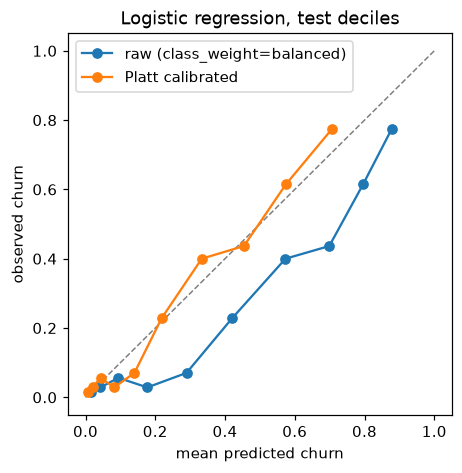

In [3]:
base, model = fitted["logistic_regression"]
raw = calibration_table(y_test, base.predict_proba(X_test)[:, 1])
cal = calibration_table(y_test, model.predict_proba(X_test)[:, 1])

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
plt.plot(raw["mean_predicted"], raw["observed_rate"], "o-", label="raw (class_weight=balanced)")
plt.plot(cal["mean_predicted"], cal["observed_rate"], "o-", label="Platt calibrated")
plt.xlabel("mean predicted churn")
plt.ylabel("observed churn")
plt.title("Logistic regression, test deciles")
plt.legend();

Ranking doesn't change, but the decision multiplies the probability by money.
With inflated probabilities, "contact if p x 35% x CLV > $60" contacts far too many people.

## Decision rule: expected value vs a threshold

{'rule': 'expected_value',
 'net_value_expected_value_rule': 36003.72,
 'best_threshold': 0.16,
 'net_value_best_threshold': 34933.32,
 'net_value_at_0.5': 24165.03}

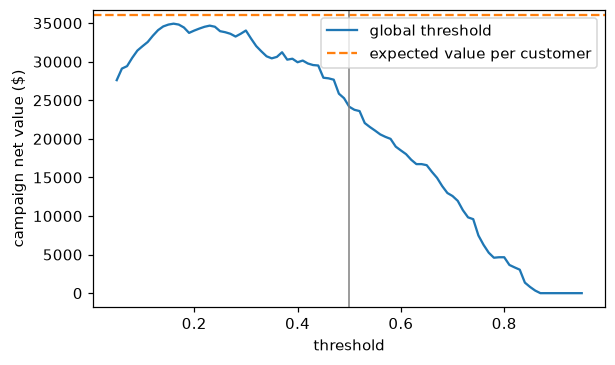

In [4]:
_, gb = fitted["gradient_boosting"]
proba = gb.predict_proba(X_test)[:, 1]
value = customer_value(X_test)
policy = choose_policy(y_test, proba, value)

grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = [net_value(y_test, proba >= t, value) for t in grid]
plt.figure(figsize=(6, 3.5))
plt.plot(grid, curve, label="global threshold")
plt.axhline(policy["net_value_expected_value_rule"], color="C1", ls="--", label="expected value per customer")
plt.axvline(0.5, color="grey", lw=1)
plt.xlabel("threshold")
plt.ylabel("campaign net value ($)")
plt.legend()
{k: policy[k] for k in ["rule", "net_value_expected_value_rule", "best_threshold", "net_value_best_threshold", "net_value_at_0.5"]}

For gradient boosting the per-customer expected-value rule beats the best global threshold, and both are far better than the 0.5 default.
It wins because it uses two things a single cut-off can't: how likely the customer is to leave *and* how much they're worth.
It isn't automatic, though: logistic regression ends up with a threshold rule (see the table above), which is why the rule is chosen per model on test instead of hard-coded.

## Test is optimistic, the holdout is honest

In [5]:
from sklearn.metrics import roc_auc_score


def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1


X_hold, y_hold = X_y(holdout)
comparison = pd.DataFrame({
    name: {
        "test_gini": gini(y_test, m.predict_proba(X_test)[:, 1]),
        "holdout_gini": gini(y_hold, m.predict_proba(X_hold)[:, 1]),
    }
    for name, (_, m) in fitted.items()
}).T
comparison["drop"] = comparison["test_gini"] - comparison["holdout_gini"]
comparison

,test_gini,holdout_gini,drop
logistic_regression,0.738,0.670,0.067
random_forest,0.736,0.663,0.073
gradient_boosting,0.731,0.667,0.064


Every model loses Gini on the holdout. The test set is used to choose the decision rule and the winning candidate, so it ends up slightly overfit to that choice.
That's why promotion only ever looks at the holdout, and why the holdout hash is logged with every promotion decision.